# Gendered rules in seven scriptures: a walkthrough

This notebook explains the whole project in plain steps, from raw texts to results. Run it top to bottom.

**Question:** how many rules does each religion's core text make that apply specifically to men or to women, and do those rules restrict or protect?

**Texts:** one core rule text per religion, in public-domain English:

| Religion | Text |
|---|---|
| Christianity | Bible (King James Version) |
| Islam | Quran (Pickthall) |
| Judaism | Torah (JPS 1917) |
| Hinduism | Manusmriti (Bühler) |
| Buddhism | Pātimokkha, the monks' and nuns' codes (Brahmali) |
| Jainism | Ākārāṅga Sūtra (Jacobi) |
| Sikhism | Sikh Rehat Maryada |

**Pipeline:** `build_dataset.py` → `tag_rules.py` → hand coding → `summarize_codes.py` → `compare_coders.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
WOMEN, MEN, BOTH, EVERYONE = '#c2410c', '#1d4ed8', '#7c3aed', '#a8a29e'

## Step 1: the texts

`build_dataset.py` downloads each text and splits it into one row per verse, rule or paragraph.

In [2]:
texts = pd.read_csv('data/religious_texts.csv')
print(f'{len(texts):,} rows')
texts.groupby(['religion', 'text_name']).size().rename('rows').to_frame()

48,207 rows


,,rows
religion,text_name,
Buddhism,Vinaya Pitaka,1698
Christianity,Bible,31102
Hinduism,Manusmriti (Laws of Manu),2504
Islam,Quran,6236
Jainism,Akaranga Sutra,645
Judaism,Torah,5846
Sikhism,Sikh Rehat Maryada,176


In [3]:
texts.groupby('religion').head(1)[['religion', 'book', 'chapter', 'verse', 'text']]

,religion,book,chapter,verse,text
0,Christianity,Genesis,1,1.0,In the beginning God created the heaven and the earth.
31102,Islam,1. Al-Faatiha,1,1.0,"In the name of Allah, the Beneficent, the Merciful."
37338,Judaism,Genesis,1,1.0,In the beginning God created the heaven and the earth.
43184,Buddhism,Bhikkhu Patimokkha (monks),0,2.0,The monks’ rules
44882,Hinduism,Laws of Manu,1,1.0,"The great sages approached Manu, who was seated with a collected mind, and, having duly worshipped him, spoke as fol..."
47386,Jainism,Book 1,"Lecture 1, Lesson 1",1.0,long-lived (<9ambftsvdmin 4 ) ! I (Sudharman) have heard the following discourse from the venerable (Mahdvtra) :
48031,Sikhism,Chapter I,Article I,1.0,Any human being who faithfully believes in


## Step 2: find candidate rules automatically

`tag_rules.py` uses keyword patterns ("thou shalt not", "it is lawful", "a monk or a nun should…") to flag rows that look like rules and mention a gender. It's a filter, not the answer: in the Bible, more than half the flagged verses turned out to be narrative or prophecy.

In [4]:
tagged = pd.read_csv('data/rules_tagged.csv', low_memory=False)
flagged = tagged[(tagged.is_rule == 1) & (tagged.gender_focus != 'neither')]
print(f'{len(flagged):,} candidate rules that mention a gender')
flagged.religion.value_counts().rename('candidates').to_frame()

2,162 candidate rules that mention a gender


,candidates
religion,
Christianity,723
Buddhism,373
Hinduism,356
Judaism,333
Jainism,260
Islam,67
Sikhism,50


## Step 3: read and code every candidate by hand

Each candidate was read and given a 4-character code:

| Position | Question | Values |
|---|---|---|
| 1 | Is it really a rule? | `0` no · `1` yes |
| 2 | Whose conduct does it govern? | `M` men only · `W` women only · `B` both, named · `G` everyone |
| 3 | Effect on women | `R` restricts · `P` protects or benefits · `X` mixed · `N` none |
| 4 | Effect on men | same |

For example, `1MPR` is a rule for men that protects women and restricts men ("retain them not to their hurt"). Buddhist rules were coded from the structure of the codes: every Pātimokkha entry restricts whoever's code it belongs to. The full rules are in `CODEBOOK.md`.

In [5]:
rules = pd.read_csv('data/coded_rules.csv')
print(f'{len(rules):,} confirmed gender-relevant rules')
rules[['religion', 'section', 'book', 'chapter', 'verse', 'code', 'text']].sample(8, random_state=3)

1,756 confirmed gender-relevant rules


,religion,section,book,chapter,verse,code,text
1751,Buddhism,NaN,Bhikkhuni Patimokkha (nuns),318,0.0,1WRN,"‘I will not give a teaching to anyone walking in front of me who is not sick,’ this is how you should train."
1411,Buddhism,NaN,Bhikkhu Patimokkha (monks),206,0.0,1MNR,"‘I will not look at another’s almsbowl finding fault,’ this is how you should train."
1155,Jainism,NaN,Book 2,"Lecture 5, Lesson 1",5.0,1BRR,"A monk or a nun should not accept any of the following plaids of fur. and other materials : plaids made of Udra, Pe^..."
487,Judaism,NaN,Exodus,40,14.0,1MNN,"And thou shalt bring his sons, and put tunics upon them."
264,Hinduism,NaN,Laws of Manu,8,371.0,1WRN,"If a wife, proud of the greatness of her relatives or (her own) excellence, violates the duty which she owes to her ..."
1110,Jainism,NaN,Book 2,"Lecture 3, Lesson 2",5.0,1BRR,"A monk or a nun, swimming in the water, should not dive lip or down, lest water should enter into their ears, eyes, ..."
1436,Buddhism,NaN,Bhikkhu Patimokkha (monks),229,0.1,1MNR,NaN
1136,Jainism,NaN,Book 2,"Lecture 4, Lesson 2",1.0,1BRR,"A monk or a nun, seeing any sort (of diseases), should not talk of them in this way : ' He has got boils, or leprosy..."


A few real examples of each kind of code:

In [6]:
examples = {
    'Women only, restricts women (1WRN)': '1WRN',
    'Men only, protects women (1MPR)': '1MPR',
    'Both genders, same duty (1BRR)': '1BRR',
    'Both genders, same right (1BPP)': '1BPP',
}
for title, c in examples.items():
    print('\n' + title)
    pool = rules[(rules.code == c) & (rules.religion != 'Buddhism')]
    for _, r in pool.sample(min(3, len(pool)), random_state=1).iterrows():
        print(f'  [{r.religion}] {r.text[:140]}')


Women only, restricts women (1WRN)
  [Judaism] And if her means suffice not for a lamb, then she shall take two turtle-doves, or two young pigeons: the one for a burnt-offering, and the o
  [Judaism] And the priest shall take the meal-offering of jealousy out of the woman’s hand, and shall wave the meal-offering before the LORD, and bring
  [Hinduism] Women should never make a hoard from (the property of) their families which is common to many, nor from their own (husbands' particular) pro

Men only, protects women (1MPR)
  [Judaism] And it shall be, if thou have no delight in her, then thou shalt let her go whither she will; but thou shalt not sell her at all for money, 
  [Islam] When ye have divorced women, and they have reached their term, then retain them in kindness or release them in kindness. Retain them not to 
  [Hinduism] But a sick wife who is kind (to her husband) and virtuous in her conduct, may be superseded (only) with her own consent and must never be di

Both genders

## Step 4: results

`summarize_codes.py` counts the codes per text. The Bible is split into Old and New Testament, because most Christian traditions don't treat the Mosaic law as binding.

In [7]:
summary = pd.read_csv('data/chart_summary.csv').set_index('label')
summary[['rules', 'women_only', 'men_only', 'both_named', 'everyone', 'restrict_women', 'protect_women']]

,rules,women_only,men_only,both_named,everyone,restrict_women,protect_women
label,,,,,,,
Buddhism · Pātimokkha,531,304,227,0,0,304,0
Christianity · whole Bible,323,29,92,18,184,58,46
Christianity · Old Testament,263,23,86,13,141,49,35
Christianity · New Testament,60,6,6,5,43,9,11
Hinduism · Manusmriti,330,34,163,6,127,75,61
Islam · Quran,44,7,16,6,15,10,17
Jainism · Ākārāṅga,237,0,10,219,8,201,20
Judaism · Torah,243,23,77,16,127,46,32
Sikhism · Rehat Maryada,48,1,3,26,18,20,12


### Rules for only one gender

Buddhism is the only tradition with more women-only rules: the nuns' code is longer than the monks' code. Manusmriti, the Torah and the Old Testament mostly address men, including many rules about women.

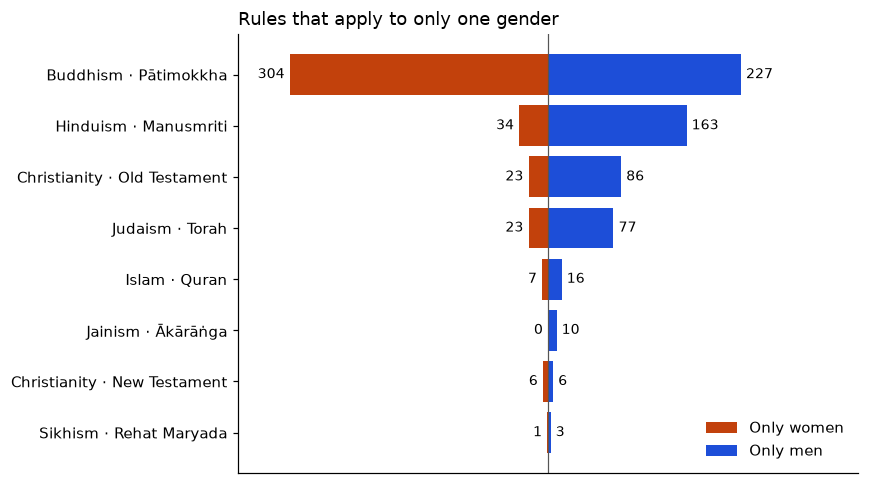

In [8]:
s = summary.drop('Christianity · whole Bible').sort_values('men_only')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(s.index, -s.women_only, color=WOMEN, label='Only women')
ax.barh(s.index, s.men_only, color=MEN, label='Only men')
for y, (w, m) in enumerate(zip(s.women_only, s.men_only)):
    ax.text(-w - 6, y, w, va='center', ha='right', fontsize=9)
    ax.text(m + 6, y, m, va='center', fontsize=9)
ax.axvline(0, color='#555', lw=0.8)
lim = max(s.women_only.max(), s.men_only.max()) * 1.2
ax.set_xlim(-lim, lim)
ax.set_xticks([])
ax.set_title('Rules that apply to only one gender', loc='left')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()

### Whose conduct the rules govern, as a share of each text

Jainism and Sikhism mostly state one rule for both genders ("a monk or a nun", "he/she"). In the Bible and Torah, many rules mention a gender only in passing ("everyone").

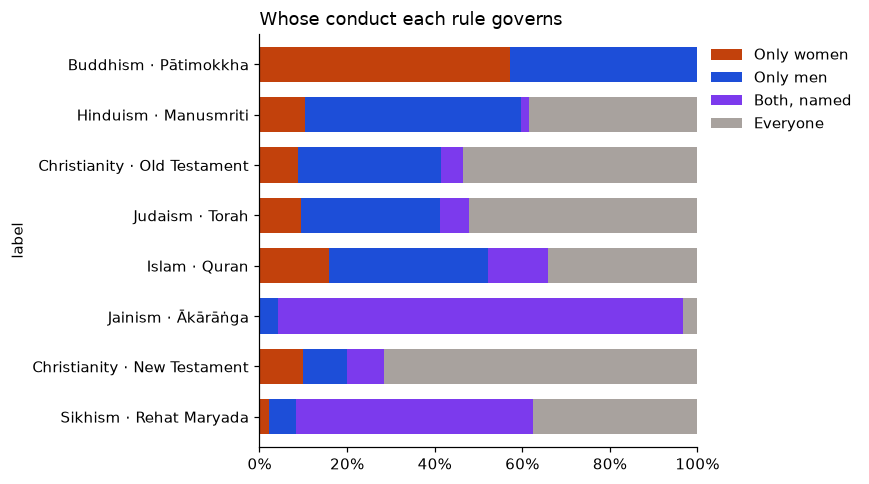

In [9]:
cols = ['women_only', 'men_only', 'both_named', 'everyone']
share = s[cols].div(s.rules, axis=0)
ax = share.plot.barh(stacked=True, color=[WOMEN, MEN, BOTH, EVERYONE], figsize=(8, 4.5), width=0.7)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Whose conduct each rule governs', loc='left')
ax.legend(['Only women', 'Only men', 'Both, named', 'Everyone'], frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()

### Do the rules restrict women or protect them?

This counts every rule with an effect on women, whoever it governs. A rule for men can protect women ("no father must take a gratuity for his daughter"). The Quran is the one text where protecting rules outnumber restricting ones.

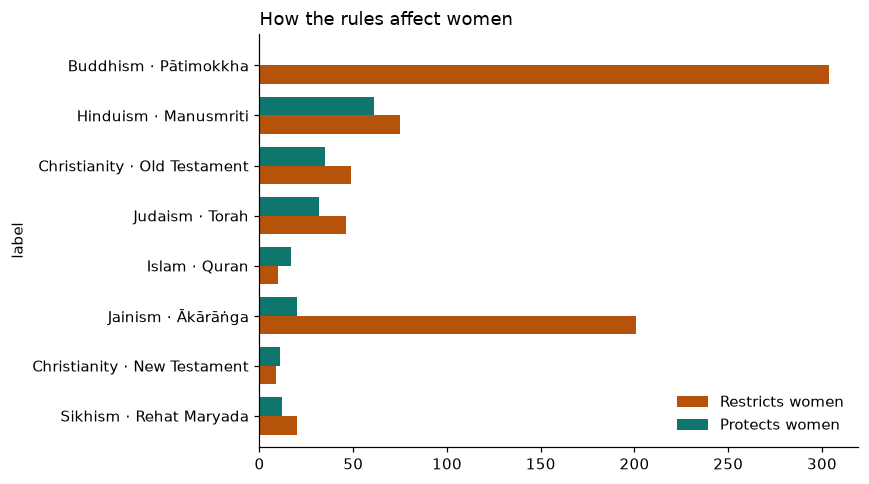

In [10]:
e = s[['restrict_women', 'protect_women']].rename(columns={'restrict_women': 'Restricts women', 'protect_women': 'Protects women'})
ax = e.plot.barh(color=['#b45309', '#0f766e'], figsize=(8, 4.5), width=0.75)
ax.set_title('How the rules affect women', loc='left')
ax.legend(frameon=False)
plt.tight_layout()

## Step 5: can we trust the coding?

A second, independent coder (a separate AI agent that never saw the first codes) coded a random sample of 200 rules from the same instructions. Cohen's κ measures agreement beyond chance: above 0.8 is strong, and 0.6–0.8 is substantial.

In [11]:
from collections import Counter

ag = pd.read_csv('data/coding/agreement.csv', dtype=str)

def parts(c):
    return [c[0]] + (list(c[1:4]) if c != '0' else ['-'] * 3)

def kappa(a, b):
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb[k] for k in set(a) | set(b)) / n / n
    return po, (po - pe) / (1 - pe)

rows = []
for k, name in enumerate(['Is it a rule?', 'Whose conduct', 'Effect on women', 'Effect on men']):
    po, kp = kappa([parts(c)[k] for c in ag.coder1], [parts(c)[k] for c in ag.coder2])
    rows.append({'code position': name, 'agreement': f'{po:.0%}', 'kappa': round(kp, 2)})
pd.DataFrame(rows)

,code position,agreement,kappa
0,Is it a rule?,98%,0.93
1,Whose conduct,90%,0.87
2,Effect on women,86%,0.82
3,Effect on men,85%,0.79


In [12]:
ag.assign(match=ag.coder1 == ag.coder2).groupby('religion').match.mean().map('{:.0%}'.format).rename('exact match').to_frame()

,exact match
religion,
Buddhism,100%
Christianity,91%
Hinduism,50%
Islam,70%
Jainism,93%
Judaism,80%
Sikhism,63%


Manusmriti agrees least. The main reason is "he": one coder read rules for "him" (the student, the householder) as men-only, the other as generic. Both are defensible, so Manusmriti's men-only count is best read as an upper bound. Some disagreements:

In [13]:
ag[ag.coder1 != ag.coder2][['religion', 'coder1', 'coder2', 'text']].head(10)

,religion,coder1,coder2,text
10,Christianity,1MNP,1MNR,"Speak unto Aaron and unto his sons, saying, On this wise ye shall bless the children of Israel, saying unto them,"
11,Sikhism,1BPP,1BRR,"(t) And finally, the karhah prashad should be distributed. All the newly launched Sikh men and women should eat the ..."
15,Sikhism,1BNN,1BRR,The boy and girl should bow before the Guru Granth Sahib to betoken their acceptance of these instructions. Thereaft...
18,Sikhism,1GRR,1GNN,"(i) A Sikh should, in no way, harbour any antipathy to the hair of the head with which his child is born. He should ..."
40,Hinduism,1WPN,1MPR,"But she who shows aversion towards a mad or outcast (husband), a eunuch, one destitute of manly strength, or one aff..."
41,Jainism,1BPP,1BRR,Now follows the seventh rule : A monk or a nun may beg for a dwellitig-place paved with clay or wood. If they get it...
42,Islam,1GRN,1MRR,"O Ye who believe! Enter not the dwellings of the Prophet for a meal without waiting for the proper time, unless perm..."
43,Hinduism,1MNR,1GNN,"But he whose father is dead, while his grandfather lives, shall, after pronouncing his father's name, mention (that ..."
48,Sikhism,1BRR,1GNN,"(p) After this, one from amongst the five beloved ones should explain to the initiates the discipline of the order: ..."
50,Judaism,1MNN,1MNR,"And the sons of Aaron the priest shall put fire upon the altar, and lay wood in order upon the fire."


## Limitations

- **One core text per religion.** The Hadith, Talmud and later legal traditions hold far more gender rules than these texts.
- **Old translations.** All are public domain, 90–400 years old. Wording such as "man" or "he" doesn't always match the original language.
- **Only rules that mention a gender** were coded. Most rules in the Bible, Torah and Quran name no gender and use "he" as the default.
- **Scanned texts.** Manusmriti (about 93% of verses recovered) and the Ākārāṅga Sūtra came from OCR scans.
- **Coding is judgement.** Agreement is strong but not perfect. See `CODEBOOK.md` and `data/coding/agreement.csv`.